<a href="https://colab.research.google.com/github/Harshit99-sys/delivery-delay-analytics/blob/main/Delivery_Delay_%26_Operations_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [25]:

from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name, encoding="latin1")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Saving DataCoSupplyChainDataset.csv to DataCoSupplyChainDataset (1).csv
Dataset loaded successfully!
Number of rows: 180519
Number of columns: 53


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [28]:

print("Dataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and missing values:")
df.info()

print("\nMissing values in the 15 columns used most often:")
print(df.isnull().sum().sort_values(ascending=False).head(15))


Dataset shape:
(180519, 53)

Column names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price',

In [29]:

columns_needed = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Late_delivery_risk",
    "Shipping Mode",
    "Order Region",
    "Category Name",
    "Market",
    "order date (DateOrders)",
    "Order Id",
    "Order Item Id"
]

analysis_df = df[columns_needed].copy()

print("Selected columns successfully!")
print("Rows:", analysis_df.shape[0])
print("Columns:", analysis_df.shape[1])

analysis_df.head()


Selected columns successfully!
Rows: 180519
Columns: 11


,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Late_delivery_risk,Shipping Mode,Order Region,Category Name,Market,order date (DateOrders),Order Id,Order Item Id
0,3,4,Advance shipping,0,Standard Class,Southeast Asia,Sporting Goods,Pacific Asia,1/31/2018 22:56,77202,180517
1,5,4,Late delivery,1,Standard Class,South Asia,Sporting Goods,Pacific Asia,1/13/2018 12:27,75939,179254
2,4,4,Shipping on time,0,Standard Class,South Asia,Sporting Goods,Pacific Asia,1/13/2018 12:06,75938,179253
3,3,4,Advance shipping,0,Standard Class,Oceania,Sporting Goods,Pacific Asia,1/13/2018 11:45,75937,179252
4,2,4,Advance shipping,0,Standard Class,Oceania,Sporting Goods,Pacific Asia,1/13/2018 11:24,75936,179251


In [30]:

analysis_df["order date (DateOrders)"] = pd.to_datetime(
    analysis_df["order date (DateOrders)"],
    errors="coerce"
)

analysis_df["Days for shipping (real)"] = pd.to_numeric(
    analysis_df["Days for shipping (real)"],
    errors="coerce"
)

analysis_df["Days for shipment (scheduled)"] = pd.to_numeric(
    analysis_df["Days for shipment (scheduled)"],
    errors="coerce"
)

analysis_df["Late_delivery_risk"] = pd.to_numeric(
    analysis_df["Late_delivery_risk"],
    errors="coerce"
)

analysis_df = analysis_df.dropna(
    subset=[
        "Days for shipping (real)",
        "Days for shipment (scheduled)",
        "Delivery Status",
        "Late_delivery_risk",
        "Shipping Mode",
        "Order Region",
        "Category Name",
        "order date (DateOrders)"
    ]
)

analysis_df = analysis_df.reset_index(drop=True)

print("Data cleaning completed.")
print("Remaining rows:", len(analysis_df))
print("Missing values in selected columns:")
print(analysis_df.isnull().sum())


Data cleaning completed.
Remaining rows: 180519
Missing values in selected columns:
Days for shipping (real)         0
Days for shipment (scheduled)    0
Delivery Status                  0
Late_delivery_risk               0
Shipping Mode                    0
Order Region                     0
Category Name                    0
Market                           0
order date (DateOrders)          0
Order Id                         0
Order Item Id                    0
dtype: int64


In [31]:

analysis_df["delay_days"] = (
    analysis_df["Days for shipping (real)"]
    - analysis_df["Days for shipment (scheduled)"]
)

analysis_df["late_shipping"] = (
    analysis_df["delay_days"] > 0
)

analysis_df["early_or_on_time"] = (
    analysis_df["delay_days"] <= 0
)

print("Delay calculation completed.")

print("\nSample delay calculations:")
print(
    analysis_df[
        [
            "Days for shipping (real)",
            "Days for shipment (scheduled)",
            "delay_days",
            "late_shipping"
        ]
    ].head(10)
)


Delay calculation completed.

Sample delay calculations:
   Days for shipping (real)  Days for shipment (scheduled)  delay_days  \
0                         3                              4          -1   
1                         5                              4           1   
2                         4                              4           0   
3                         3                              4          -1   
4                         2                              4          -2   
5                         6                              4           2   
6                         2                              1           1   
7                         2                              1           1   
8                         3                              2           1   
9                         2                              1           1   

   late_shipping  
0          False  
1           True  
2          False  
3          False  
4          False  
5           Tr

In [32]:

delivered_df = analysis_df[
    analysis_df["Delivery Status"] != "Shipping canceled"
].copy()

total_rows = len(analysis_df)
cancelled_rows = len(analysis_df) - len(delivered_df)

late_count = delivered_df["late_shipping"].sum()
on_time_count = delivered_df["early_or_on_time"].sum()

late_percentage = late_count / len(delivered_df) * 100
on_time_percentage = on_time_count / len(delivered_df) * 100

average_shipping_days = delivered_df[
    "Days for shipping (real)"
].mean()

average_delay_days = delivered_df.loc[
    delivered_df["late_shipping"], "delay_days"
].mean()

print("DELIVERY PERFORMANCE REPORT")
print("-" * 35)
print("Total order-item rows:", total_rows)
print("Cancelled rows:", cancelled_rows)
print("Non-cancelled rows:", len(delivered_df))
print("Late-shipping rows:", int(late_count))
print("On-time or early rows:", int(on_time_count))
print(f"Late-shipping rate: {late_percentage:.2f}%")
print(f"On-time/early rate: {on_time_percentage:.2f}%")
print(f"Average shipping duration: {average_shipping_days:.2f} days")
print(f"Average delay among late rows: {average_delay_days:.2f} days")


DELIVERY PERFORMANCE REPORT
-----------------------------------
Total order-item rows: 180519
Cancelled rows: 7754
Non-cancelled rows: 172765
Late-shipping rows: 98977
On-time or early rows: 73788
Late-shipping rate: 57.29%
On-time/early rate: 42.71%
Average shipping duration: 3.50 days
Average delay among late rows: 1.62 days


Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64


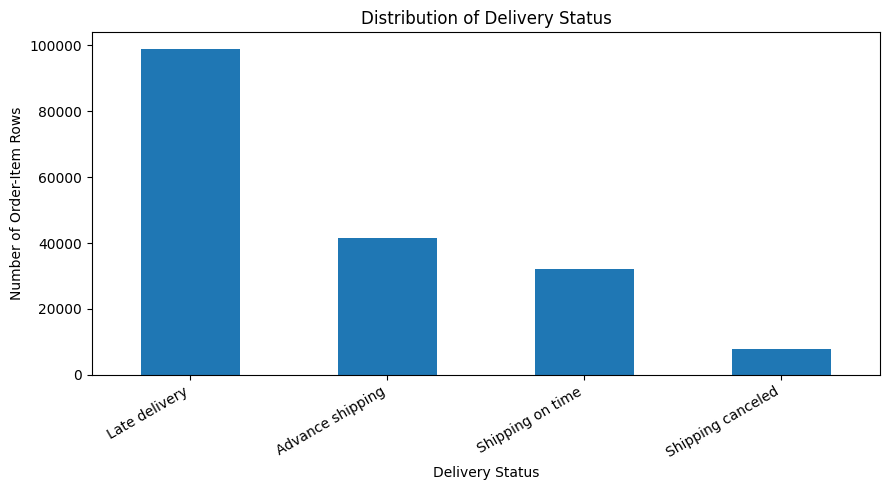

In [33]:

status_counts = analysis_df["Delivery Status"].value_counts()

print(status_counts)

status_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Distribution of Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Order-Item Rows")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


                total_rows  late_rows  average_delay_days  late_rate_percent
Shipping Mode                                                               
First Class          26513      26513                1.00             100.00
Second Class         33806      26987                1.99              79.83
Same Day              9293       4454                0.48              47.93
Standard Class      103153      41023               -0.01              39.77


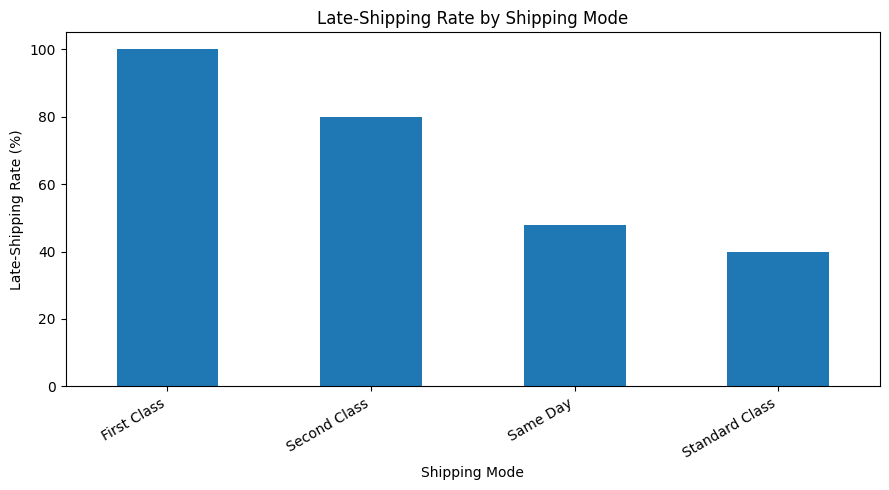

In [34]:

mode_summary = delivered_df.groupby("Shipping Mode").agg(
    total_rows=("late_shipping", "size"),
    late_rows=("late_shipping", "sum"),
    average_delay_days=("delay_days", "mean")
)

mode_summary["late_rate_percent"] = (
    mode_summary["late_rows"] / mode_summary["total_rows"] * 100
)

mode_summary = mode_summary.sort_values(
    "late_rate_percent",
    ascending=False
)

print(mode_summary.round(2))

mode_summary["late_rate_percent"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Late-Shipping Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Late-Shipping Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


Regions with the highest late-shipping rates:
                total_rows  late_rows  late_rate_percent
Order Region                                            
Central Africa        1616        972              60.15
Western Europe       25867      15140              58.53
South of  USA         3855       2256              58.52
South Asia            7455       4350              58.35
East Africa           1781       1036              58.17
East of USA           6617       3849              58.17
Southeast Asia        9136       5297              57.98
West Asia             5746       3322              57.81
Eastern Europe        3785       2182              57.65
US Center             5653       3252              57.53


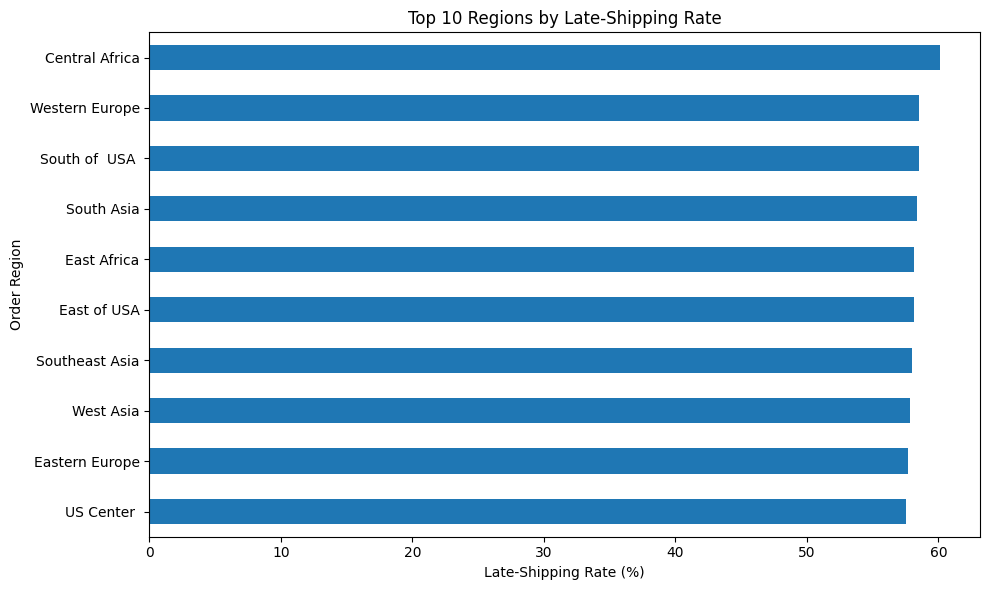

In [35]:

region_summary = delivered_df.groupby("Order Region").agg(
    total_rows=("late_shipping", "size"),
    late_rows=("late_shipping", "sum")
)

region_summary["late_rate_percent"] = (
    region_summary["late_rows"] / region_summary["total_rows"] * 100
)

region_summary = region_summary[
    region_summary["total_rows"] >= 500
].sort_values(
    "late_rate_percent",
    ascending=False
)

print("Regions with the highest late-shipping rates:")
print(region_summary.head(10).round(2))

region_summary.head(10)["late_rate_percent"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Regions by Late-Shipping Rate")
plt.xlabel("Late-Shipping Rate (%)")
plt.ylabel("Order Region")
plt.tight_layout()
plt.show()


Top 10 product categories by late-shipping rate:
                     total_rows  late_rows  late_rate_percent
Category Name                                                
Golf Bags & Carts            61         42              68.85
Lacrosse                    329        206              62.61
Pet Supplies                472        290              61.44
Cameras                     562        344              61.21
Accessories                1697       1014              59.75
Music                       417        248              59.47
Fitness Accessories         296        176              59.46
Boxing & MMA                402        238              59.20
Crafts                      458        271              59.17
As Seen on  TV!              66         39              59.09


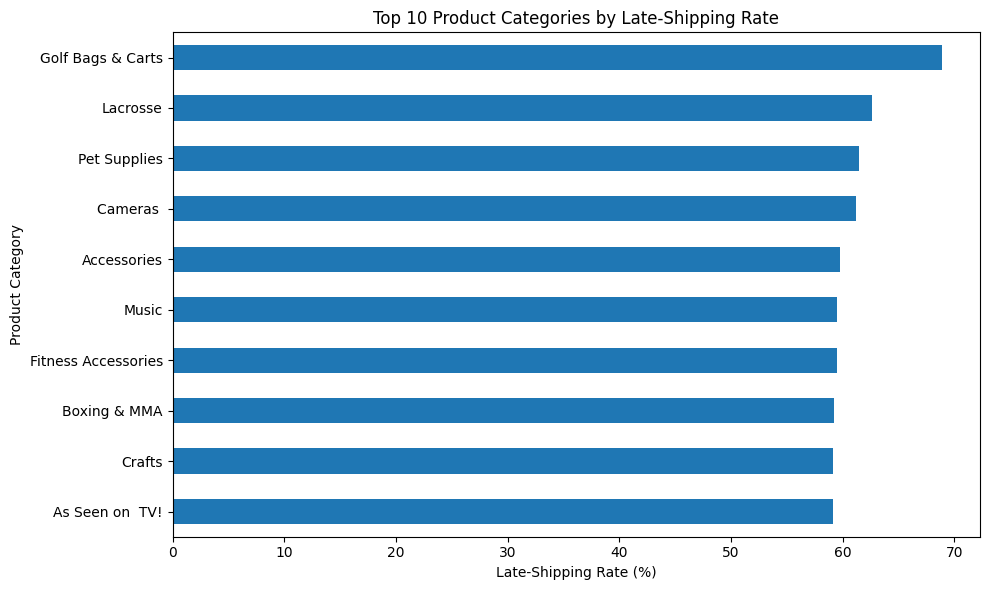

In [36]:

category_summary = delivered_df.groupby("Category Name").agg(
    total_rows=("late_shipping", "size"),
    late_rows=("late_shipping", "sum")
)

category_summary["late_rate_percent"] = (
    category_summary["late_rows"] / category_summary["total_rows"] * 100
)

category_summary = category_summary.sort_values(
    "late_rate_percent",
    ascending=False
)

print("Top 10 product categories by late-shipping rate:")
print(category_summary.head(10).round(2))

category_summary.head(10)["late_rate_percent"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Product Categories by Late-Shipping Rate")
plt.xlabel("Late-Shipping Rate (%)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


Late-shipping rate by weekday:
               total_rows  late_rows  late_rate_percent
order_weekday                                          
Monday              24558      14196              57.81
Tuesday             24585      13913              56.59
Wednesday           24447      14011              57.31
Thursday            24713      14165              57.32
Friday              24875      14303              57.50
Saturday            24754      14089              56.92
Sunday              24833      14300              57.58


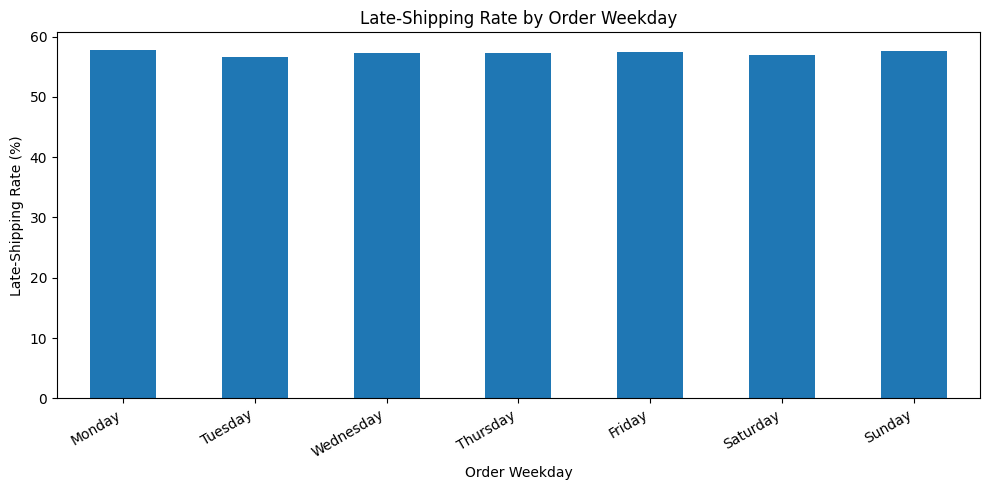

In [37]:

delivered_df["order_weekday"] = (
    delivered_df["order date (DateOrders)"].dt.day_name()
)

delivered_df["order_month"] = (
    delivered_df["order date (DateOrders)"].dt.to_period("M")
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_summary = delivered_df.groupby("order_weekday").agg(
    total_rows=("late_shipping", "size"),
    late_rows=("late_shipping", "sum")
)

weekday_summary["late_rate_percent"] = (
    weekday_summary["late_rows"] / weekday_summary["total_rows"] * 100
)

weekday_summary = weekday_summary.reindex(weekday_order)

print("Late-shipping rate by weekday:")
print(weekday_summary.round(2))

weekday_summary["late_rate_percent"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Late-Shipping Rate by Order Weekday")
plt.xlabel("Order Weekday")
plt.ylabel("Late-Shipping Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


Monthly shipping performance:
             total_rows  late_rows  late_rate_percent
order_month                                          
2015-01            5114       2880              56.32
2015-02            4487       2594              57.81
2015-03            5127       2936              57.27
2015-04            4915       2760              56.15
2015-05            5087       2951              58.01
2015-06            4908       2778              56.60
2015-07            5124       2939              57.36
2015-08            5025       2936              58.43
2015-09            4926       2914              59.16
2015-10            5073       2906              57.28
2015-11            5019       2841              56.60
2015-12            5149       2937              57.04


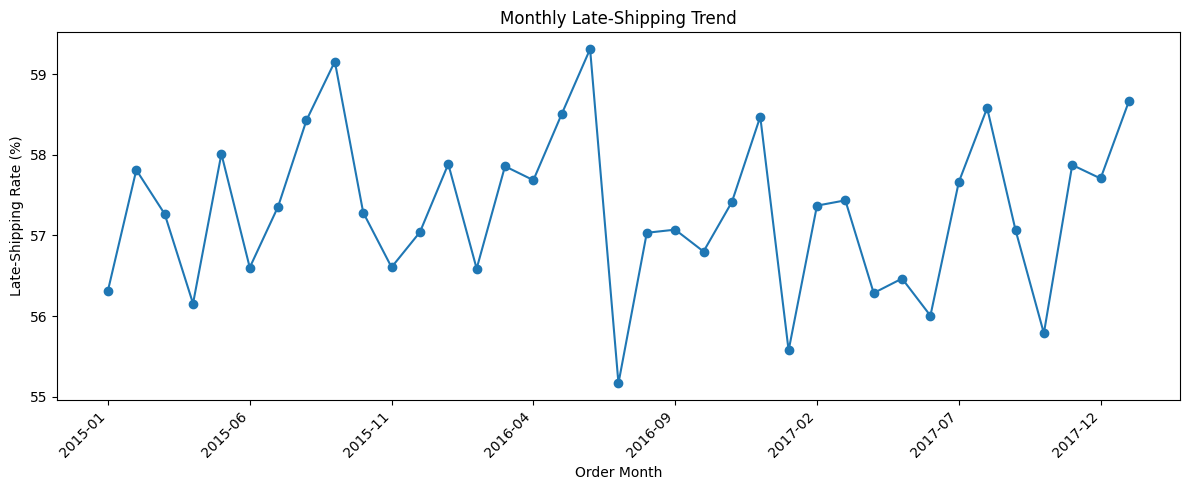

In [38]:

monthly_summary = delivered_df.groupby("order_month").agg(
    total_rows=("late_shipping", "size"),
    late_rows=("late_shipping", "sum")
)

monthly_summary["late_rate_percent"] = (
    monthly_summary["late_rows"] / monthly_summary["total_rows"] * 100
)

monthly_summary.index = monthly_summary.index.astype(str)

print("Monthly shipping performance:")
print(monthly_summary.head(12).round(2))

monthly_summary["late_rate_percent"].plot(
    figsize=(12, 5),
    marker="o"
)

plt.title("Monthly Late-Shipping Trend")
plt.xlabel("Order Month")
plt.ylabel("Late-Shipping Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


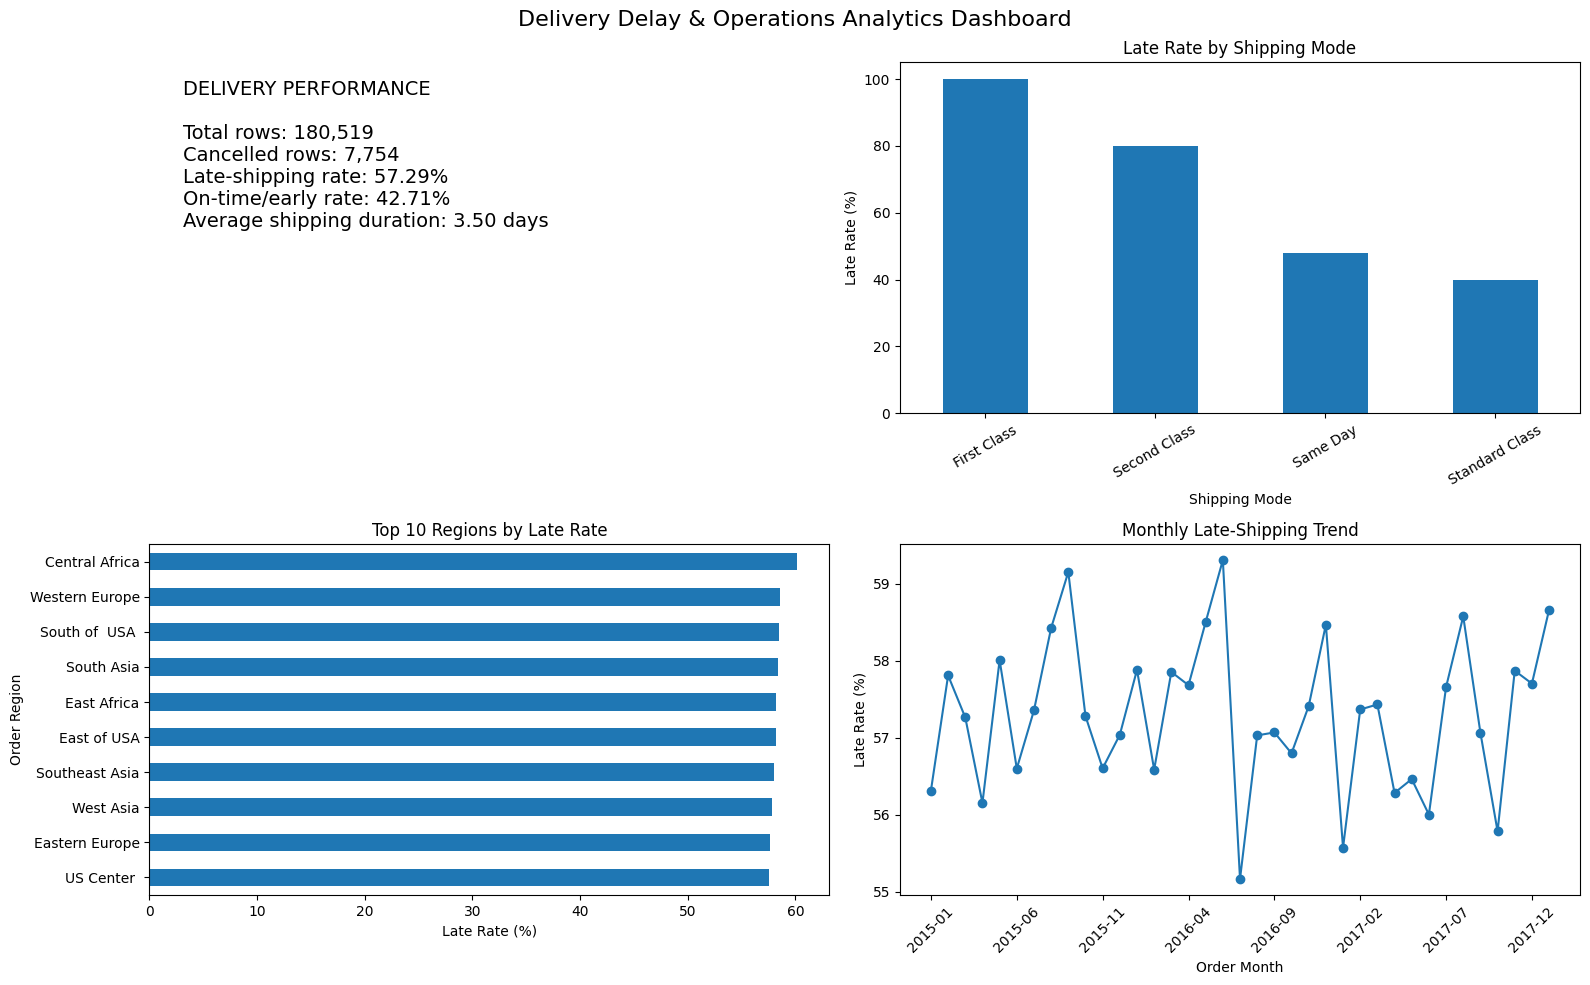

In [39]:

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# KPI summary
axes[0, 0].axis("off")

kpi_text = (
    f"DELIVERY PERFORMANCE\n\n"
    f"Total rows: {len(analysis_df):,}\n"
    f"Cancelled rows: {cancelled_rows:,}\n"
    f"Late-shipping rate: {late_percentage:.2f}%\n"
    f"On-time/early rate: {on_time_percentage:.2f}%\n"
    f"Average shipping duration: {average_shipping_days:.2f} days"
)

axes[0, 0].text(
    0.05, 0.95, kpi_text,
    va="top",
    fontsize=14
)

# Shipping mode chart
mode_summary["late_rate_percent"].plot(
    kind="bar",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Late Rate by Shipping Mode")
axes[0, 1].set_xlabel("Shipping Mode")
axes[0, 1].set_ylabel("Late Rate (%)")
axes[0, 1].tick_params(axis="x", rotation=30)

# Region chart
region_summary.head(10)["late_rate_percent"].sort_values().plot(
    kind="barh",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Top 10 Regions by Late Rate")
axes[1, 0].set_xlabel("Late Rate (%)")
axes[1, 0].set_ylabel("Order Region")

# Monthly trend
monthly_summary["late_rate_percent"].plot(
    ax=axes[1, 1],
    marker="o"
)

axes[1, 1].set_title("Monthly Late-Shipping Trend")
axes[1, 1].set_xlabel("Order Month")
axes[1, 1].set_ylabel("Late Rate (%)")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.suptitle("Delivery Delay & Operations Analytics Dashboard",
             fontsize=16)

plt.tight_layout()
plt.show()


In [40]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

model_df = delivered_df.copy()

model_df["order_month_num"] = (
    model_df["order date (DateOrders)"].dt.month
)

model_df["order_weekday_num"] = (
    model_df["order date (DateOrders)"].dt.dayofweek
)

features = [
    "Days for shipment (scheduled)",
    "Shipping Mode",
    "Order Region",
    "Category Name",
    "Market",
    "order_month_num",
    "order_weekday_num"
]

X = model_df[features]
y = model_df["late_shipping"].astype(int)

numeric_features = [
    "Days for shipment (scheduled)",
    "order_month_num",
    "order_weekday_num"
]

categorical_features = [
    "Shipping Mode",
    "Order Region",
    "Category Name",
    "Market"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_features),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=6,
            min_samples_leaf=100,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("MODEL EVALUATION")
print("-" * 30)
print(f"Training rows: {len(X_train):,}")
print(f"Testing rows: {len(X_test):,}")
print(f"Accuracy: {accuracy_score(y_test, predictions):.4f}")
print(f"Precision: {precision_score(y_test, predictions, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, predictions, zero_division=0):.4f}")
print(f"F1-score: {f1_score(y_test, predictions, zero_division=0):.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["On-time or early", "Late shipping"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, predictions))


MODEL EVALUATION
------------------------------
Training rows: 138,212
Testing rows: 34,553
Accuracy: 0.6994
Precision: 0.8805
Recall: 0.5500
F1-score: 0.6771

Classification report:
                  precision    recall  f1-score   support

On-time or early       0.60      0.90      0.72     14758
   Late shipping       0.88      0.55      0.68     19795

        accuracy                           0.70     34553
       macro avg       0.74      0.72      0.70     34553
    weighted avg       0.76      0.70      0.69     34553

Confusion matrix:
[[13280  1478]
 [ 8907 10888]]


Top 15 model features:
                                      Feature  Importance
0      numeric__Days for shipment (scheduled)      0.9895
1                    numeric__order_month_num      0.0035
2                  numeric__order_weekday_num      0.0023
24  categorical__Order Region_Southern Europe      0.0010
19    categorical__Order Region_South America      0.0007
7            categorical__Order Region_Canada      0.0004
84                   categorical__Market_USCA      0.0004
8         categorical__Order Region_Caribbean      0.0003
83           categorical__Market_Pacific Asia      0.0003
29   categorical__Order Region_Western Europe      0.0003
80                 categorical__Market_Africa      0.0002
42          categorical__Category Name_Cleats      0.0002
28     categorical__Order Region_West of USA       0.0002
15   categorical__Order Region_Eastern Europe      0.0002
13      categorical__Order Region_East of USA      0.0002


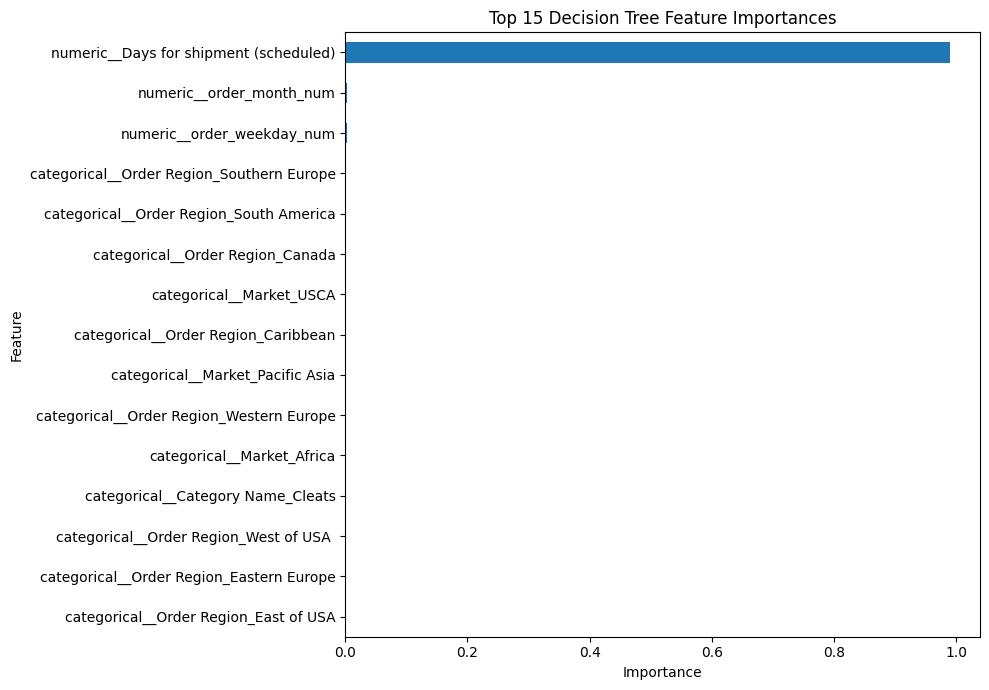

In [41]:

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_values = model.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print("Top 15 model features:")
print(importance_df.head(15).round(4))

importance_df.head(15).sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(10, 7),
    legend=False
)

plt.title("Top 15 Decision Tree Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [42]:

mode_hotspots = mode_summary.reset_index().rename(
    columns={"Shipping Mode": "Problem Area"}
)

mode_hotspots["Area Type"] = "Shipping Mode"

region_hotspots = region_summary.reset_index().rename(
    columns={"Order Region": "Problem Area"}
)

region_hotspots["Area Type"] = "Order Region"

category_hotspots = category_summary.reset_index().rename(
    columns={"Category Name": "Problem Area"}
)

category_hotspots["Area Type"] = "Product Category"

hotspot_table = pd.concat(
    [
        mode_hotspots[
            ["Area Type", "Problem Area", "total_rows",
             "late_rows", "late_rate_percent"]
        ],
        region_hotspots[
            ["Area Type", "Problem Area", "total_rows",
             "late_rows", "late_rate_percent"]
        ],
        category_hotspots[
            ["Area Type", "Problem Area", "total_rows",
             "late_rows", "late_rate_percent"]
        ]
    ],
    ignore_index=True
)

hotspot_table = hotspot_table.sort_values(
    "late_rate_percent",
    ascending=False
)

print("TOP POTENTIAL OPERATIONAL HOTSPOTS")
print(
    hotspot_table.head(20).round(2).to_string(index=False)
)


TOP POTENTIAL OPERATIONAL HOTSPOTS
       Area Type        Problem Area  total_rows  late_rows  late_rate_percent
   Shipping Mode         First Class       26513      26513             100.00
   Shipping Mode        Second Class       33806      26987              79.83
Product Category   Golf Bags & Carts          61         42              68.85
Product Category            Lacrosse         329        206              62.61
Product Category        Pet Supplies         472        290              61.44
Product Category            Cameras          562        344              61.21
    Order Region      Central Africa        1616        972              60.15
Product Category         Accessories        1697       1014              59.75
Product Category               Music         417        248              59.47
Product Category Fitness Accessories         296        176              59.46
Product Category        Boxing & MMA         402        238              59.20
Product Category 

In [44]:

import os

output_folder = "/content/DeliveryProject"
os.makedirs(output_folder, exist_ok=True)

mode_summary.to_csv(
    f"{output_folder}/shipping_mode_summary.csv"
)

region_summary.to_csv(
    f"{output_folder}/region_summary.csv"
)

category_summary.to_csv(
    f"{output_folder}/category_summary.csv"
)

monthly_summary.to_csv(
    f"{output_folder}/monthly_summary.csv"
)

hotspot_table.to_csv(
    f"{output_folder}/operational_hotspots.csv",
    index=False
)

importance_df.to_csv(
    f"{output_folder}/model_feature_importance.csv",
    index=False
)

print("Analysis results saved successfully!")
print("Files saved at:", output_folder)
print("\nSaved files:")

for file in os.listdir(output_folder):
    print(file)


Analysis results saved successfully!
Files saved at: /content/DeliveryProject

Saved files:
category_summary.csv
shipping_mode_summary.csv
monthly_summary.csv
model_feature_importance.csv
operational_hotspots.csv
region_summary.csv


## 7. Conclusion

This project analyzed supply chain shipping data to understand shipping delays and identify potential operational problem areas. The analysis showed that approximately 57.29% of non-cancelled order-item records had a positive shipping delay, while 42.71% were shipped on time or earlier than scheduled.

The project compared shipping performance across shipping modes, order regions, product categories, weekdays, and months. A decision tree model was also developed to estimate late-shipping risk using selected pre-shipping information.

The findings can help prioritize further investigation into shipping performance and operational bottlenecks. However, additional data on warehouses, carriers, routes, and actual delivery events would be needed to identify root causes more precisely. Overall, this project demonstrates how data analysis and machine learning can support supply chain performance monitoring and operational decision-making.